# Spam Message Classification — ML Analysis Dashboard

> **A production-style NLP notebook for spam/ham classification**

This notebook upgrades the original script into a complete machine-learning workflow:

-  Dataset quality and class-balance analysis
-  Robust text preprocessing
-  Word-level + character-level TF-IDF features
-  Comparison of **Multinomial Naive Bayes, Logistic Regression, and Linear SVM**
-  Accuracy, Precision, Recall, F1, ROC-AUC and confusion matrix
-  Error analysis
-  Custom-message prediction
-  Export of the best trained pipeline with `joblib`

> **Important:** your current dataset columns are `Category` and `Message`, with `ham`/`spam` labels. The project is therefore an **SMS/message spam classifier** unless you replace the dataset with actual email data.


In [5]:
# ============================================================
# 1. Setup
# ============================================================
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import re
import html
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, HTML, Markdown

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = Path("../data/sample_emails.csv")
MODEL_PATH = Path("../models/spam_classifier_best.joblib")

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

display(HTML("""
<div style="padding:22px;border-radius:16px;background:linear-gradient(135deg,#111827,#1f2937);color:white">
<h1 style="margin:0">🛡️ Spam Classification Lab</h1>
<p style="margin:8px 0 0;color:#d1d5db">Clean → Explore → Train → Compare → Evaluate → Predict</p>
</div>
"""))

print("Libraries loaded successfully.")
print("Dataset:", DATA_PATH)
print("Model output:", MODEL_PATH)


Libraries loaded successfully.
Dataset: ..\data\sample_emails.csv
Model output: ..\models\spam_classifier_best.joblib


## 2. Load and validate the dataset

The original training code expects exactly two columns:

- `Category` → `ham` or `spam`
- `Message` → message text

We validate the schema instead of silently assuming it is correct.


In [6]:
# ============================================================
# 2. Load and validate data
# ============================================================
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place your CSV at ../data/sample_emails.csv."
    )

df = pd.read_csv(DATA_PATH, encoding="latin-1")

required = {"Category", "Message"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

df = df[["Category", "Message"]].copy()
df.columns = ["label", "message"]

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].fillna("").astype(str).str.strip()

invalid_labels = set(df["label"]) - {"ham", "spam"}
if invalid_labels:
    raise ValueError(f"Unexpected labels found: {sorted(invalid_labels)}")

df = df[df["message"].ne("")].copy()
df["target"] = df["label"].map({"ham": 0, "spam": 1})

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
display(df.head(10))


Rows: 5,572
Columns: 3


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1
6,ham,Even my brother is not like to speak with me. ...,0
7,ham,As per your request 'Melle Melle (Oru Minnamin...,0
8,spam,WINNER!! As a valued network customer you have...,1
9,spam,Had your mobile 11 months or more? U R entitle...,1


Metric,Value
Total messages,5572
Duplicate messages,415
Empty messages,0
Spam,747
Ham,4825


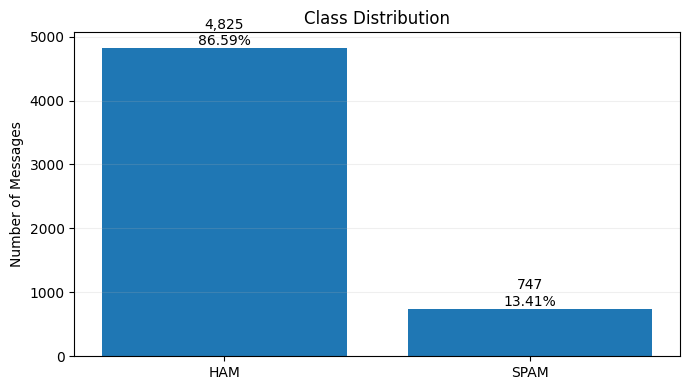

In [7]:
# ============================================================
# 3. Dataset quality + class balance
# ============================================================
duplicates = df.duplicated(subset=["message"]).sum()
missing_messages = df["message"].isna().sum()

summary = pd.DataFrame({
    "Metric": ["Total messages", "Duplicate messages", "Empty messages", "Spam", "Ham"],
    "Value": [
        len(df),
        duplicates,
        missing_messages,
        int((df["target"] == 1).sum()),
        int((df["target"] == 0).sum())
    ]
})

display(summary.style.hide(axis="index"))

class_counts = df["label"].value_counts()
class_pct = (class_counts / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_counts.index.str.upper(), class_counts.values)
ax.set_title("Class Distribution")
ax.set_ylabel("Number of Messages")
ax.grid(axis="y", alpha=0.2)

for bar, count, pct in zip(bars, class_counts.values, class_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count:,}\n{pct}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

display(HTML(f"""
<div style="display:flex;gap:12px;flex-wrap:wrap">
<div style="padding:15px 20px;border-radius:12px;background:#eef2ff"><b>📨 Messages</b><br><span style="font-size:22px">{len(df):,}</span></div>
<div style="padding:15px 20px;border-radius:12px;background:#fef2f2"><b>🚨 Spam</b><br><span style="font-size:22px">{int((df.target==1).sum()):,}</span></div>
<div style="padding:15px 20px;border-radius:12px;background:#ecfdf5"><b>✅ Ham</b><br><span style="font-size:22px">{int((df.target==0).sum()):,}</span></div>
<div style="padding:15px 20px;border-radius:12px;background:#fff7ed"><b>♻️ Duplicates</b><br><span style="font-size:22px">{duplicates:,}</span></div>
</div>
"""))


## 3. Text preprocessing

Instead of deleting useful signals, we normalize common spam indicators:

- URLs → `URL`
- numbers → `NUMBER`
- email addresses → `EMAIL`
- whitespace normalization
- lowercase conversion

The original project already recognized URLs and numbers; this version adds email normalization and keeps the raw message available for analysis. fileciteturn0file3L3-L18


,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in number a wkly comp to win fa cup...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it's been number wee...
6,ham,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...,as per your request 'melle melle (oru minnamin...


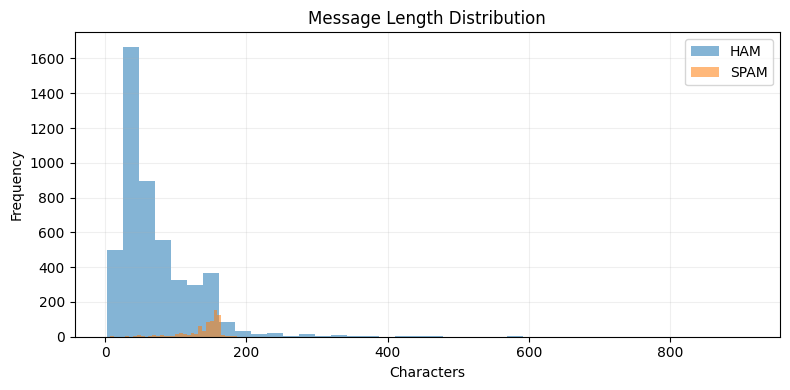

In [8]:
# ============================================================
# 4. Robust text normalization
# ============================================================
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b", " email ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)
    text = re.sub(r"\b\d+(?:[.,]\d+)?\b", " number ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].map(clean_text)
df["message_length"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

display(df[["label", "message", "clean_message"]].head(8))

fig, ax = plt.subplots(figsize=(8, 4))
for label in ["ham", "spam"]:
    subset = df.loc[df["label"] == label, "message_length"]
    ax.hist(subset, bins=40, alpha=0.55, label=label.upper())

ax.set_title("Message Length Distribution")
ax.set_xlabel("Characters")
ax.set_ylabel("Frequency")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 4. Train/test split

We use a **stratified** split so that spam/ham proportions are preserved in both sets. The test set remains untouched until final evaluation.


In [9]:
# ============================================================
# 5. Stratified train/test split
# ============================================================
X = df["message"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples : {len(X_test):,}")

print("\nTrain class distribution:")
display(y_train.value_counts(normalize=True).rename({0: "ham", 1: "spam"}).mul(100).round(2))

print("\nTest class distribution:")
display(y_test.value_counts(normalize=True).rename({0: "ham", 1: "spam"}).mul(100).round(2))


Training samples: 4,457
Testing samples : 1,115

Train class distribution:


target
ham     86.58
spam    13.42
Name: proportion, dtype: float64


Test class distribution:


target
ham     86.64
spam    13.36
Name: proportion, dtype: float64

## 5. Feature engineering

For short messages, combining **word n-grams** with **character n-grams** is often stronger than relying on word TF-IDF alone.

- Word TF-IDF captures phrases such as `claim prize`, `free entry`, etc.
- Character TF-IDF helps with misspellings, obfuscation, unusual punctuation and partial word patterns.

All vectorization stays inside the model pipeline, preventing train/test preprocessing leakage.


In [10]:
# ============================================================
# 6. Feature extractors
# ============================================================
word_tfidf = TfidfVectorizer(
    preprocessor=clean_text,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    max_features=30000,
    strip_accents="unicode"
)

char_tfidf = TfidfVectorizer(
    preprocessor=clean_text,
    lowercase=False,
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    sublinear_tf=True,
    max_features=30000
)

features = FeatureUnion([
    ("word", word_tfidf),
    ("char", char_tfidf)
])

print("Word + character TF-IDF feature pipeline ready.")


Word + character TF-IDF feature pipeline ready.


## 6. Model comparison

We evaluate three strong classical NLP baselines:

1. **Multinomial Naive Bayes**
2. **Logistic Regression**
3. **Linear SVM**

The best model is selected using **F1 score**, not accuracy alone. This is important because a spam detector should balance catching spam with avoiding false positives.


In [11]:
# ============================================================
# 7. Train and compare models
# ============================================================
models = {
    "Multinomial NB": Pipeline([
        ("features", features),
        ("clf", MultinomialNB(alpha=0.15))
    ]),
    "Logistic Regression": Pipeline([
        ("features", features),
        ("clf", LogisticRegression(
            C=3.0,
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Linear SVM": Pipeline([
        ("features", features),
        ("clf", LinearSVC(
            C=1.5,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    auc = roc_auc_score(y_test, scores)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc,
        "Train Time (s)": elapsed
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)

styled = (
    results_df.style
    .format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}",
        "ROC-AUC": "{:.2%}",
        "Train Time (s)": "{:.2f}"
    })
    .background_gradient(subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
)

display(styled)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,Linear SVM,99.28%,99.30%,95.30%,97.26%,99.57%,0.65
1,Logistic Regression,98.92%,95.97%,95.97%,95.97%,99.51%,0.77
2,Multinomial NB,98.83%,97.22%,93.96%,95.56%,99.05%,0.56


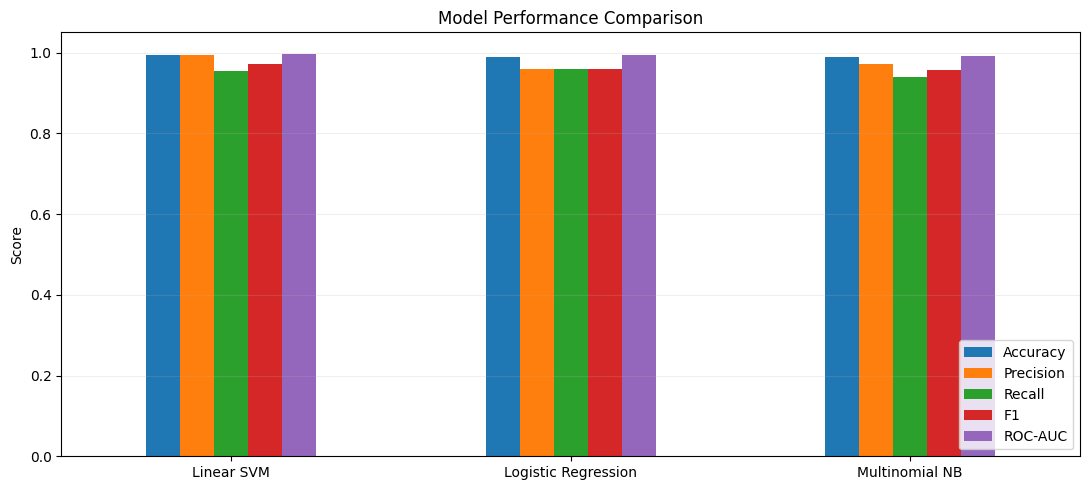

In [12]:
# ============================================================
# 8. Model comparison chart
# ============================================================
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]

ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

BEST_MODEL_NAME = results_df.iloc[0]["Model"]
BEST_MODEL = trained_models[BEST_MODEL_NAME]

display(HTML(f"""
<div style="padding:18px;border-radius:14px;background:#ecfdf5;border:1px solid #a7f3d0">
<h3 style="margin:0">🏆 Best Model: {BEST_MODEL_NAME}</h3>
<p style="margin:8px 0 0">Selected using the highest test-set F1 score among the evaluated candidates.</p>
</div>
"""))


## 7. Detailed evaluation of the selected model

For a spam filter:

- **Precision** answers: “When the model says spam, how often is it actually spam?”
- **Recall** answers: “How much of the real spam does the model catch?”
- **F1** balances precision and recall.
- **ROC-AUC** measures ranking quality across decision thresholds.


Selected model: Linear SVM

              precision    recall  f1-score   support

         HAM     0.9928    0.9990    0.9959       966
        SPAM     0.9930    0.9530    0.9726       149

    accuracy                         0.9928      1115
   macro avg     0.9929    0.9760    0.9842      1115
weighted avg     0.9928    0.9928    0.9928      1115



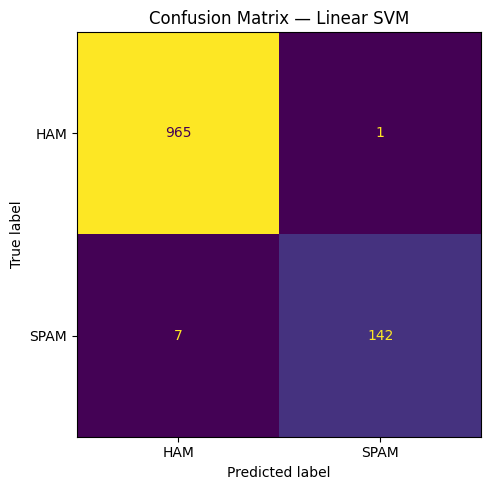

In [13]:
# ============================================================
# 9. Detailed evaluation
# ============================================================
best_pred = BEST_MODEL.predict(X_test)

print(f"Selected model: {BEST_MODEL_NAME}\n")
print(classification_report(
    y_test,
    best_pred,
    target_names=["HAM", "SPAM"],
    digits=4
))

cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["HAM", "SPAM"]
)
disp.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title(f"Confusion Matrix — {BEST_MODEL_NAME}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

display(HTML(f"""
<div style="display:grid;grid-template-columns:repeat(4,1fr);gap:10px">
<div style="padding:15px;border-radius:12px;background:#eef2ff"><b>TN</b><br><span style="font-size:24px">{tn}</span></div>
<div style="padding:15px;border-radius:12px;background:#fff7ed"><b>FP</b><br><span style="font-size:24px">{fp}</span></div>
<div style="padding:15px;border-radius:12px;background:#fff7ed"><b>FN</b><br><span style="font-size:24px">{fn}</span></div>
<div style="padding:15px;border-radius:12px;background:#ecfdf5"><b>TP</b><br><span style="font-size:24px">{tp}</span></div>
</div>
"""))


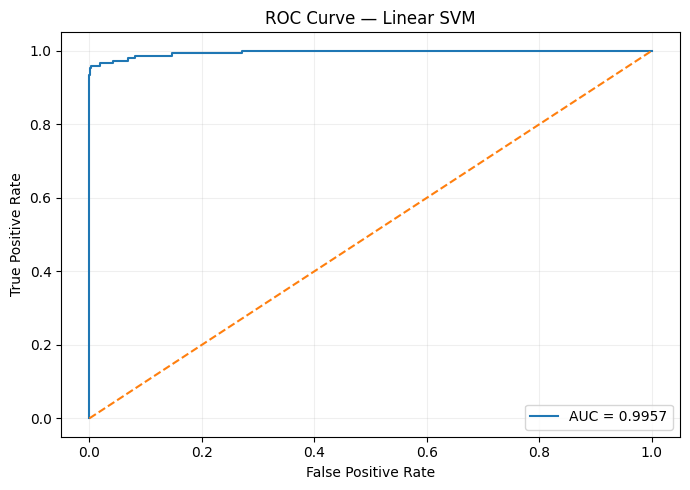

In [14]:
# ============================================================
# 10. ROC curve
# ============================================================
if hasattr(BEST_MODEL, "predict_proba"):
    test_scores = BEST_MODEL.predict_proba(X_test)[:, 1]
else:
    test_scores = BEST_MODEL.decision_function(X_test)

fpr, tpr, _ = roc_curve(y_test, test_scores)
auc = roc_auc_score(y_test, test_scores)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_title(f"ROC Curve — {BEST_MODEL_NAME}")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 8. Error analysis

A good classifier is not just about one score. We inspect messages that were misclassified so that we can understand failure modes such as:

- promotional language that resembles legitimate messages
- legitimate messages containing words such as `free`, `offer`, `win`
- spam with unusually subtle wording


In [15]:
# ============================================================
# 11. Error analysis
# ============================================================
error_df = pd.DataFrame({
    "message": X_test.values,
    "actual": y_test.values,
    "predicted": best_pred
})

error_df["actual"] = error_df["actual"].map({0: "HAM", 1: "SPAM"})
error_df["predicted"] = error_df["predicted"].map({0: "HAM", 1: "SPAM"})

errors = error_df[error_df["actual"] != error_df["predicted"]].copy()

print(f"Misclassified messages: {len(errors):,}")
display(errors.head(20).style.set_properties(**{
    "text-align": "left",
    "white-space": "pre-wrap"
}))


Misclassified messages: 8


,message,actual,predicted
219,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,SPAM,HAM
235,"Latest News! Police station toilet stolen, cops have nothing to go on!",SPAM,HAM
478,For sale - arsenal dartboard. Good condition but no doubles or trebles!,SPAM,HAM
796,U 2.,HAM,SPAM
841,ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are bringing in a real breath of sunshine.,SPAM,HAM
852,"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",SPAM,HAM
1035,RCT' THNQ Adrian for U text. Rgds Vatian,SPAM,HAM
1069,"Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!",SPAM,HAM


## 9. Custom prediction

Use the final trained pipeline on messages that were not part of the dataset.

The pipeline contains preprocessing + feature extraction + classifier, so deployment only needs to load **one object**.


In [16]:
# ============================================================
# 12. Prediction helper
# ============================================================
def predict_message(message, model=BEST_MODEL):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please provide a non-empty message.")

    prediction = int(model.predict([message])[0])

    if hasattr(model, "predict_proba"):
        confidence = float(model.predict_proba([message])[0].max())
    else:
        decision = float(model.decision_function([message])[0])
        # SVM decision value is not a calibrated probability.
        confidence = float(1 / (1 + np.exp(-abs(decision))))

    label = "SPAM" if prediction == 1 else "NOT SPAM"
    return label, confidence

examples = [
    "Congratulations! You have won a free prize. Click here to claim now!",
    "Hey, are we still meeting at 6 pm today?",
    "URGENT! You have been selected for a cash reward. Call now!",
]

for msg in examples:
    label, confidence = predict_message(msg)
    print(f"{label:10} | confidence-like score: {confidence:.2%} | {msg}")


SPAM       | confidence-like score: 68.22% | Congratulations! You have won a free prize. Click here to claim now!
NOT SPAM   | confidence-like score: 75.44% | Hey, are we still meeting at 6 pm today?
SPAM       | confidence-like score: 66.19% | URGENT! You have been selected for a cash reward. Call now!


In [17]:
# ============================================================
# 13. Interactive notebook UI (ipywidgets)
# ============================================================
try:
    import ipywidgets as widgets
    from IPython.display import clear_output

    text_box = widgets.Textarea(
        value="",
        placeholder="Paste an SMS/email message here...",
        description="Message:",
        layout=widgets.Layout(width="100%", height="150px")
    )

    button = widgets.Button(
        description="🔍 Analyze Message",
        button_style="primary",
        layout=widgets.Layout(width="220px")
    )

    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            try:
                label, confidence = predict_message(text_box.value)
                if label == "SPAM":
                    bg, icon = "#fef2f2", "🚨"
                else:
                    bg, icon = "#ecfdf5", "✅"

                display(HTML(f"""
                <div style="padding:22px;border-radius:16px;background:{bg};margin-top:12px">
                    <h2 style="margin:0">{icon} {html.escape(label)}</h2>
                    <p style="margin:8px 0 0">Confidence-like score: <b>{confidence:.2%}</b></p>
                </div>
                """))
            except Exception as e:
                display(HTML(f'<div style="color:#b91c1c"><b>Error:</b> {html.escape(str(e))}</div>'))

    button.on_click(on_click)
    display(text_box, button, output)

except ImportError:
    print("ipywidgets is not installed. Run: pip install ipywidgets")


Textarea(value='', description='Message:', layout=Layout(height='150px', width='100%'), placeholder='Paste an …

Button(button_style='primary', description='🔍 Analyze Message', layout=Layout(width='220px'), style=ButtonStyl…

Output()

## 10. Save the production pipeline

This exports the complete preprocessing + TF-IDF + classifier pipeline.

That is safer than saving a vectorizer and classifier separately because deployment uses exactly the same transformation sequence as training.


In [18]:
# ============================================================
# 14. Save final model
# ============================================================
joblib.dump(BEST_MODEL, MODEL_PATH)

size_kb = MODEL_PATH.stat().st_size / 1024

display(HTML(f"""
<div style="padding:18px;border-radius:14px;background:#eff6ff;border:1px solid #bfdbfe">
<h3 style="margin:0">💾 Model exported</h3>
<p style="margin:8px 0 0"><b>{MODEL_PATH}</b></p>
<p style="margin:4px 0 0">File size: {size_kb:.1f} KB</p>
</div>
"""))


## 11. Final project conclusions

### What improved compared with the original implementation?

| Area | Original | Upgraded notebook |
|---|---|---|
| Split | Basic 80/20 | Stratified 80/20 |
| Features | Word TF-IDF | Word + character TF-IDF |
| Models | Linear SVM only | NB + Logistic Regression + Linear SVM |
| Selection | Accuracy/report | F1 + precision + recall + ROC-AUC |
| Evaluation | Basic report | Confusion matrix + ROC + error analysis |
| Deployment | Saved pipeline | Best pipeline automatically selected and exported |
| UI | Flask form | Notebook dashboard + interactive predictor |
| Data validation | Minimal | Schema, labels, empty messages, duplicates |

### Important modeling note

The best model should **not** be declared from a hard-coded assumption. Run this notebook on your actual dataset and let the evaluation table determine the winner.

For a production spam system, the next upgrade would be **cross-validation + hyperparameter tuning + probability calibration/threshold tuning**, especially if false positives are costly.
